# Предсказание калорийности блюд

## Этап 1  Исследовательский анализ (EDA)

#### Описание проекта

Цель проекта - разработать модель машинного обучения, которая предсказывает общую калорийность блюда по фотографии, списку ингредиентов и массе порции.

Проект решает задачу регрессии. На выходе модель возвращает одно числовое значение - предполагаемое количество килокалорий в блюде.

Целевая метрика проекта:

```text
MAE < 50 ккал

MAE показывает среднюю абсолютную разницу между настоящей и предсказанной калорийностью.

#### Данные

Датасет занимает около 1,35 ГБ и содержит:

- 3262 блюда;
- 2755 объектов в train;
- 507 объектов в test;
- фотографии блюд;
- массу каждой порции;
- список ингредиентов;
- настоящую калорийность.

 `data/dish.csv`

Основная таблица содержит следующие столбцы:

| Столбец | Описание |
|---|---|
| `dish_id` | Уникальный идентификатор блюда |
| `total_calories` | Общая калорийность блюда |
| `total_mass` | Общая масса порции |
| `ingredients` | Список идентификаторов ингредиентов |
| `split` | Принадлежность к train или test |

 `data/ingredients.csv`

Справочник ингредиентов:

| Столбец | Описание |
|---|---|
| `id` | Числовой идентификатор ингредиента |
| `ingr` | Название ингредиента |

В датасете используется около 200 различных ингредиентов. Все идентификаторы из `dish.csv` присутствуют в справочнике.

## 1 Проверка загрузки и подготовки данных

На этом этапе проверим работу подготовленного пайплайна данных:

- загрузим таблицы `dish.csv` и `ingredients.csv`;
- преобразуем идентификаторы ингредиентов в названия;
- разделим исходную обучающую выборку на train и validation;
- создадим DataLoader для train, validation и test;
- загрузим первый batch;
- проверим размеры тензоров изображения, массы и целевой переменной.

Такая проверка позволяет убедиться, что фотографии, текстовые признаки, масса и калорийность правильно связаны между собой до начала построения модели.

In [39]:
from scripts.dataset import create_dataloaders
from scripts.dataset import load_and_prepare_data
import torch

from scripts.model import CalorieModel


dataframe = load_and_prepare_data(
    data_dir="data",
    check_images=True,
)

loaders, dataframes, statistics = create_dataloaders(
    dataframe=dataframe,
    batch_size=4,
    image_size=224,
    validation_size=0.2,
    seed=42,
    num_workers=0,
)

batch = next(iter(loaders["train"]))

print("Все объекты:", len(dataframe))
print("Train:", len(dataframes["train"]))
print("Validation:", len(dataframes["validation"]))
print("Test:", len(dataframes["test"]))

print("Средняя масса train:", statistics["mass_mean"])
print("Стандартное отклонение:", statistics["mass_std"])

print("Image batch:", batch["image"].shape)
print("Mass batch:", batch["mass"].shape)
print("Target batch:", batch["target"].shape)

print("Первый dish_id:", batch["dish_id"][0])
print("Первый текст:", batch["text"][0])
print("Первая масса:", batch["raw_mass"][0].item())
print("Первый target:", batch["target"][0].item())

Все объекты: 3262
Train: 2204
Validation: 551
Test: 507
Средняя масса train: 218.90290381125226
Стандартное отклонение: 165.86368299054013
Image batch: torch.Size([4, 3, 224, 224])
Mass batch: torch.Size([4, 1])
Target batch: torch.Size([4])
Первый dish_id: dish_1563824339
Первый текст: onions, cherry tomatoes, olives, bell peppers
Первая масса: 175.0
Первый target: 85.33999633789062


### Результаты проверки

Датасет содержит 3262 блюда:

- train: 2204 объекта;
- validation: 551 объект;
- test: 507 объектов.

Разделение выполнено корректно: официальный test не участвует в обучении и выборе параметров модели.

Полученный batch содержит четыре объекта. Размерности тензоров соответствуют ожидаемым:

- изображения: `[4, 3, 224, 224]`;
- масса: `[4, 1]`;
- целевая переменная: `[4]`.

Каждое изображение представлено тремя RGB-каналами и приведено к размеру 224 x 224 пикселя. Масса представлена одним числовым признаком для каждого блюда, а target содержит настоящую калорийность.

Идентификаторы ингредиентов успешно преобразованы в понятный текст. Например, для одного из блюд получен список `onions, cherry tomatoes, olives, bell peppers`.

Средняя масса в обучающей выборке составляет около 218,9 г, а стандартное отклонение - около 165,9 г. Большое стандартное отклонение указывает на существенную разницу в размерах порций. Для обучения модели масса нормализуется с использованием статистик только обучающей выборки.

Таким образом, загрузка и подготовка данных работают корректно. Можно переходить к построению baseline-модели и последующей реализации мультимодальной нейросети.


## 2 Исследовательский анализ данных

На этом этапе изучим распределение массы и калорийности, связь между ними, количество ингредиентов и примеры фотографий.

Целевую переменную анализируем только на исходной обучающей выборке. Официальный test не используем для выбора решений.

### 2. Общая статистика

In [40]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from PIL import Image


eda_df = dataframe.copy()

train_eda = eda_df[
    eda_df["split"] == "train"
].copy()

train_eda["calories_per_100g"] = (
    train_eda["total_calories"]
    / train_eda["total_mass"]
    * 100
)

print("Размер всего датасета:", len(eda_df))
print(eda_df["split"].value_counts())

print("\nПропуски:")
display(eda_df.isna().sum().to_frame("Количество"))

print("Дубликаты dish_id:", eda_df["dish_id"].duplicated().sum())

print("\nОсновные статистики train:")
display(
    train_eda[
        [
            "total_calories",
            "total_mass",
            "calories_per_100g",
            "ingredient_count",
        ]
    ].describe().round(2)
)

correlation = train_eda["total_mass"].corr(
    train_eda["total_calories"]
)

print("Корреляция массы и калорийности:", round(correlation, 3))

Размер всего датасета: 3262
split
train    2755
test      507
Name: count, dtype: int64

Пропуски:


,Количество
dish_id,0
total_calories,0
total_mass,0
ingredients,0
split,0
ingredient_text,0
ingredient_count,0
image_path,0


Дубликаты dish_id: 0

Основные статистики train:


,total_calories,total_mass,calories_per_100g,ingredient_count
count,2755.00,2755.00,2755.00,2755.00
mean,254.93,218.01,127.95,7.36
std,221.01,163.09,103.84,6.91
min,0.00,5.00,0.00,1.00
25%,81.81,94.00,59.18,1.00
50%,208.12,179.00,107.39,4.00
75%,376.57,308.00,154.56,12.00
max,3943.33,3051.00,578.10,34.00


Корреляция массы и калорийности: 0.77


 Комментарий к статистикам

В данных отсутствуют пропуски и дубликаты `dish_id`, поэтому дополнительное заполнение значений не требуется.

Средняя калорийность составляет около 255 ккал, а медианная - около 208 ккал. Средняя масса также выше медианной: 218 г против 179 г. Это указывает на смещение распределений вправо из-за небольшого количества крупных и высококалорийных блюд.

Максимальные значения массы и калорийности заметно отличаются от третьего квартиля: 3051 г и 3943 ккал. Эти объекты необходимо отдельно посмотреть, но не следует удалять автоматически, поскольку они могут соответствовать реальным большим порциям.

Среднее блюдо содержит около семи ингредиентов, однако медианное количество равно четырём. Некоторые сложные блюда содержат до 34 ингредиентов.

Корреляция массы и калорийности равна 0,77. Это сильная положительная связь, поэтому масса будет важным признаком модели. При этом связь не является полной: блюда одинаковой массы могут иметь разную калорийность из-за различного состава.

Также в данных присутствуют блюда с нулевой калорийностью. Перед обучением стоит посмотреть эти объекты и определить, являются ли они корректными наблюдениями или ошибками разметки.

### 3. Основные графики

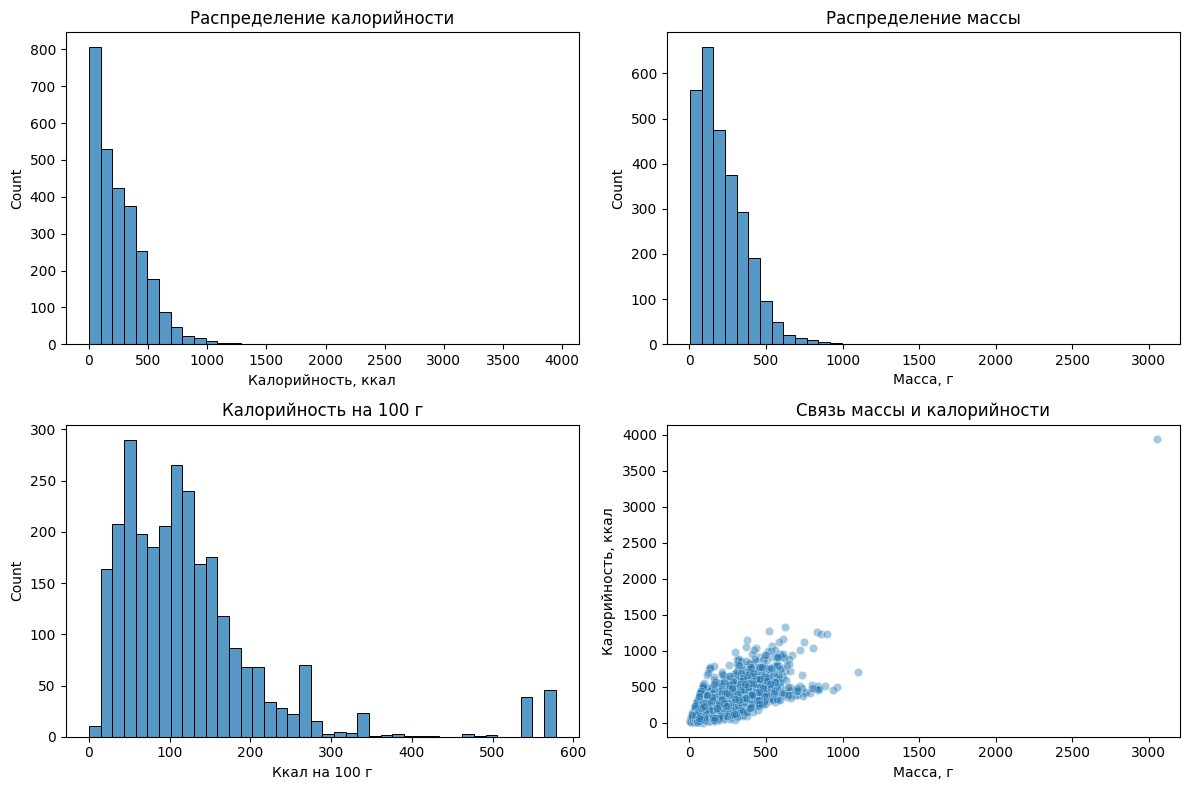

In [41]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

sns.histplot(
    train_eda["total_calories"],
    bins=40,
    ax=axes[0, 0],
)

axes[0, 0].set_title("Распределение калорийности")
axes[0, 0].set_xlabel("Калорийность, ккал")

sns.histplot(
    train_eda["total_mass"],
    bins=40,
    ax=axes[0, 1],
)

axes[0, 1].set_title("Распределение массы")
axes[0, 1].set_xlabel("Масса, г")

sns.histplot(
    train_eda["calories_per_100g"],
    bins=40,
    ax=axes[1, 0],
)

axes[1, 0].set_title("Калорийность на 100 г")
axes[1, 0].set_xlabel("Ккал на 100 г")

sns.scatterplot(
    data=train_eda,
    x="total_mass",
    y="total_calories",
    alpha=0.4,
    ax=axes[1, 1],
)

axes[1, 1].set_title("Связь массы и калорийности")
axes[1, 1].set_xlabel("Масса, г")
axes[1, 1].set_ylabel("Калорийность, ккал")

plt.tight_layout()
plt.show()

Распределения массы и общей калорийности заметно смещены вправо. Большинство блюд имеет массу до 500 г и калорийность до 700 ккал, однако присутствует небольшое количество значительно более крупных значений.

На графике связи массы и калорийности наблюдается выраженная положительная зависимость: с увеличением массы блюда его калорийность обычно возрастает. При этом для блюд одинаковой массы значения калорийности могут существенно различаться. Следовательно, масса является важным, но недостаточным признаком. Для более точного прогноза необходимо учитывать ингредиенты и фотографию.

На диаграмме присутствует один особенно крупный объект с массой около 3000 г и калорийностью около 3900 ккал. Он продолжает общую зависимость между массой и калорийностью, поэтому автоматически считать его ошибкой и удалять не следует. Этот пример нужно рассмотреть отдельно.

Калорийность на 100 г распределена неравномерно. Основная часть блюд находится примерно в диапазоне от 30 до 250 ккал на 100 г, но встречаются более калорийные блюда со значениями выше 500 ккал на 100 г. Такие значения могут соответствовать продуктам с высоким содержанием жиров или сахара.


### 4. Анализ ингредиентов

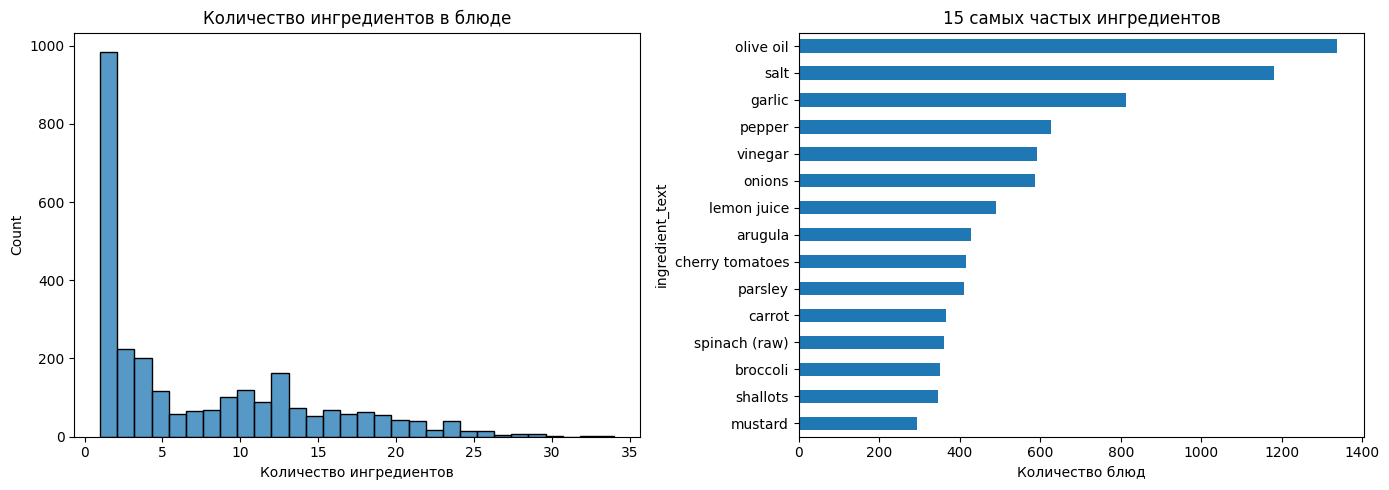

In [42]:
ingredient_frequency = (
    train_eda["ingredient_text"]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(15)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

sns.histplot(
    train_eda["ingredient_count"],
    bins=30,
    ax=axes[0],
)

axes[0].set_title("Количество ингредиентов в блюде")
axes[0].set_xlabel("Количество ингредиентов")

ingredient_frequency.sort_values().plot.barh(
    ax=axes[1]
)

axes[1].set_title("15 самых частых ингредиентов")
axes[1].set_xlabel("Количество блюд")

plt.tight_layout()
plt.show()

Большая часть блюд содержит небольшое количество ингредиентов. Самая многочисленная группа состоит из блюд с одним или двумя ингредиентами. При этом распределение имеет длинный правый хвост: отдельные сложные блюда содержат более 20 ингредиентов, а максимальное количество достигает 34.

Также заметна небольшая группа блюд примерно с 10-13 ингредиентами. Вероятно, это салаты, смешанные блюда или блюда с большим количеством приправ и дополнительных компонентов.

Самыми частыми ингредиентами являются оливковое масло, соль и чеснок. Оливковое масло особенно важно для предсказания, поскольку даже небольшое его количество может значительно увеличить калорийность блюда. Однако датасет содержит только факт присутствия ингредиента, но не его точную массу.

Частые ингредиенты встречаются во многих блюдах, поэтому само наличие соли или чеснока не позволит точно определить калорийность. Для модели важнее сочетание ингредиентов вместе с общей массой и изображением блюда.


### 5. Примеры фотографий

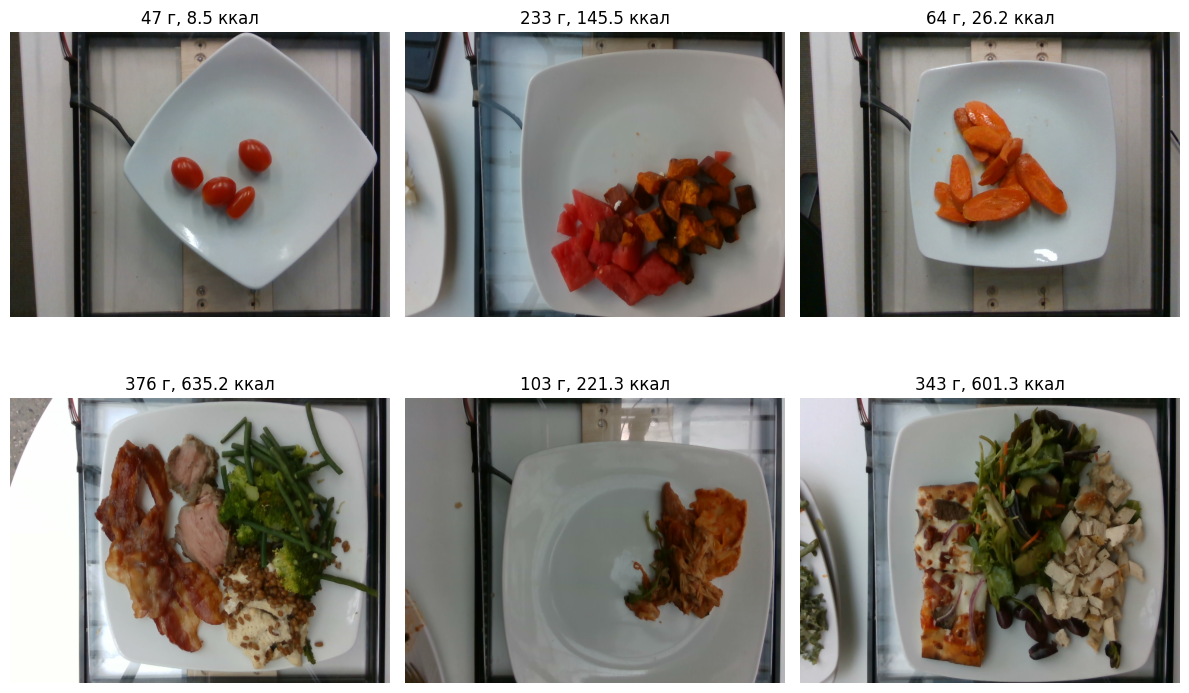

In [43]:
sample = train_eda.sample(
    n=6,
    random_state=42,
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 8),
)

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"{row['total_mass']:.0f} г, "
        f"{row['total_calories']:.1f} ккал"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

Фотографии имеют похожую структуру: блюда сняты сверху, используются преимущественно светлые тарелки и одинаковый фон. Такая однородность упрощает обучение image encoder, поскольку модели не нужно адаптироваться к сильно различающимся ракурсам.

Размер порции частично заметен на фотографии. Например, блюда массой 343-376 г занимают большую площадь тарелки, чем блюда массой 47-64 г. Поэтому изображение может дополнять числовой признак массы.

При этом визуальный объём не всегда соответствует калорийности. Порция массой 103 г содержит 221,3 ккал, тогда как более крупная порция массой 233 г содержит 145,5 ккал. Это показывает, что для прогноза важен не только размер порции, но и её состав.

Некоторые калорийные компоненты, например масло, соус или способ приготовления, сложно определить только по фотографии. Поэтому изображение необходимо использовать вместе с ингредиентами и массой.

На отдельных фотографиях видны края соседних тарелок и элементы фона. Умеренные аугментации помогут модели меньше зависеть от положения тарелки и посторонних деталей.

## 2. Реализация плайн обучения

Перед обучением нейросети проверим несколько простых моделей:

1. Предсказание медианной калорийности.
2. Линейную регрессию по массе.
3. Ridge-регрессию по ингредиентам и массе.

Baseline нужен для оценки пользы нейросети. Мультимодальная модель должна показывать качество лучше или как минимум не хуже простых методов.

Импорты и подготовка

In [44]:
from scipy.sparse import csr_matrix, hstack
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MultiLabelBinarizer


train_df = dataframes["train"]
validation_df = dataframes["validation"]

y_train = train_df["total_calories"].to_numpy()
y_validation = validation_df["total_calories"].to_numpy()

results = []

Baseline по медиане

In [45]:
median_calories = np.median(y_train)

median_predictions = np.full(
    len(validation_df),
    median_calories,
)

median_mae = mean_absolute_error(
    y_validation,
    median_predictions,
)

results.append(
    {
        "model": "Median",
        "validation_mae": median_mae,
    }
)

print("Медианная калорийность:", round(median_calories, 2))
print("MAE:", round(median_mae, 2))

Медианная калорийность: 208.12
MAE: 166.8


Линейная модель по массе

In [46]:
mass_model = LinearRegression()

mass_model.fit(
    train_df[["total_mass"]],
    y_train,
)

mass_predictions = mass_model.predict(
    validation_df[["total_mass"]]
)

mass_mae = mean_absolute_error(
    y_validation,
    mass_predictions,
)

results.append(
    {
        "model": "Mass Linear Regression",
        "validation_mae": mass_mae,
    }
)

print("Коэффициент массы:", round(mass_model.coef_[0], 3))
print("Свободный коэффициент:", round(mass_model.intercept_, 2))
print("MAE:", round(mass_mae, 2))

Коэффициент массы: 1.033
Свободный коэффициент: 28.2
MAE: 105.13


Ингредиенты и масса

In [47]:
train_ingredients = train_df[
    "ingredient_text"
].str.split(", ")

validation_ingredients = validation_df[
    "ingredient_text"
].str.split(", ")

ingredient_encoder = MultiLabelBinarizer(
    sparse_output=True
)

X_train_ingredients = ingredient_encoder.fit_transform(
    train_ingredients
)

X_validation_ingredients = ingredient_encoder.transform(
    validation_ingredients
)

mass_mean = train_df["total_mass"].mean()
mass_std = train_df["total_mass"].std()

train_mass = (
    (train_df["total_mass"] - mass_mean) / mass_std
).to_numpy().reshape(-1, 1)

validation_mass = (
    (validation_df["total_mass"] - mass_mean) / mass_std
).to_numpy().reshape(-1, 1)

X_train = hstack(
    [
        X_train_ingredients,
        csr_matrix(train_mass),
    ]
).tocsr()

X_validation = hstack(
    [
        X_validation_ingredients,
        csr_matrix(validation_mass),
    ]
).tocsr()

ingredient_mass_model = Ridge(alpha=10.0)

ingredient_mass_model.fit(
    X_train,
    y_train,
)

ingredient_mass_predictions = ingredient_mass_model.predict(
    X_validation
)

ingredient_mass_mae = mean_absolute_error(
    y_validation,
    ingredient_mass_predictions,
)

results.append(
    {
        "model": "Ingredients + Mass Ridge",
        "validation_mae": ingredient_mass_mae,
    }
)

print("Количество ингредиентов:", len(ingredient_encoder.classes_))
print("MAE:", round(ingredient_mass_mae, 2))

Количество ингредиентов: 195
MAE: 50.04


d:\МИФИ_учеба\3_семестр\02_Работа_с_изображениями_и_текстами\02_проект\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['banana with peel', 'wheat bread'] will be ignored
  warnings.warn(


Савнение результатов

In [48]:
results_df = pd.DataFrame(results)

results_df["validation_mae"] = (
    results_df["validation_mae"].round(2)
)

results_df = results_df.sort_values(
    "validation_mae"
).reset_index(drop=True)

display(results_df)

,model,validation_mae
0,Ingredients + Mass Ridge,50.04
1,Mass Linear Regression,105.13
2,Median,166.80


#### Комментарий по baseline-моделям

Модель, которая предсказывает медианную калорийность для всех блюд, получила MAE 166,80 ккал. Это базовый результат без использования признаков.

Линейная регрессия по массе уменьшила ошибку до 105,13 ккал. Масса действительно связана с калорийностью, но её недостаточно для точного прогноза.

Лучший результат показала Ridge-регрессия по ингредиентам и массе: MAE 50,04 ккал. Информация о составе блюда уменьшила ошибку примерно в два раза относительно модели только по массе.

Целевое значение MAE < 50 пока не достигнуто, но baseline находится очень близко к нему. Следующая мультимодальная модель должна использовать изображение, текст и массу, чтобы дополнительно уменьшить ошибку.

In [49]:
from scripts.dataset import (
    create_dataloaders,
    load_and_prepare_data,
)


dish_df = load_and_prepare_data("data")

loaders, dataframes, statistics = create_dataloaders(
    dataframe=dish_df,
    batch_size=4,
    image_size=224,
    validation_size=0.2,
    seed=42,
    num_workers=0,
)

print("Train batches:", len(loaders["train"]))

Train batches: 551


In [50]:


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CalorieModel().to(device)

batch = next(iter(loaders["train"]))

with torch.inference_mode():
    predictions = model(
        images=batch["image"].to(device),
        texts=batch["text"],
        masses=batch["mass"].to(device),
    )

print("Устройство:", device)
print("Форма результата:", predictions.shape)
print("Предсказания:", predictions)
print("Настоящие значения:", batch["target"])

Устройство: cuda
Форма результата: torch.Size([4])
Предсказания: tensor([ 0.0201, -0.0020,  0.0069, -0.0228], device='cuda:0')
Настоящие значения: tensor([ 85.3400, 571.3939, 569.5115,  38.7200])


In [51]:
from torch import nn
from torch.optim import AdamW


# Новые слои обучаются, замороженные энкодеры работают в режиме оценки
model.train()
model.image_encoder.eval()
model.text_encoder.eval()

criterion = nn.L1Loss()

trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = AdamW(
    trainable_parameters,
    lr=1e-3,
)

batch = next(iter(loaders["train"]))

images = batch["image"].to(device)
texts = batch["text"]
masses = batch["mass"].to(device)
targets = batch["target"].to(device)

optimizer.zero_grad(set_to_none=True)

predictions = model(
    images=images,
    texts=texts,
    masses=masses,
)

loss = criterion(predictions, targets)

loss.backward()

gradient = (
    model.regression_head[-1]
    .weight.grad
    .abs()
    .mean()
    .item()
)

optimizer.step()

print("Loss:", loss.item())
print("Средний градиент:", gradient)
print("Тестовый шаг обучения выполнен")

Loss: 114.55282592773438
Средний градиент: 0.038178861141204834
Тестовый шаг обучения выполнен


#### Комментирий по проверке обучения

Тестовый шаг обучения выполнен успешно. Значение `L1Loss` составило `114.66`, а средний градиент последнего слоя - `0.0498`.

Ненулевой градиент показывает, что ошибка распространяется через обучаемые слои модели. Оптимизатор может обновлять веса регрессионной головы, поэтому модель технически готова к обучению.

Полученное значение loss пока не характеризует качество модели, поскольку оно рассчитано только на одном случайном batch до полноценного обучения. Следующая проверка - переобучение модели на небольшой выборке из 16 объектов.

In [52]:
import torch
from torch import nn
from torch.optim import AdamW
from torch.utils.data import DataLoader

from scripts.dataset import (
    DishDataset,
    get_validation_transforms,
)
from scripts.model import CalorieModel


# Берём 16 объектов без случайных аугментаций
small_df = dataframes["train"].iloc[:16].copy()

small_dataset = DishDataset(
    dataframe=small_df,
    transform=get_validation_transforms(image_size=224),
    mass_mean=statistics["mass_mean"],
    mass_std=statistics["mass_std"],
)

small_loader = DataLoader(
    small_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
)

# Создаём отдельную модель только для теста
small_model = CalorieModel().to(device)

criterion = nn.L1Loss()

optimizer = AdamW(
    [
        parameter
        for parameter in small_model.parameters()
        if parameter.requires_grad
    ],
    lr=3e-3,
)

loss_history = []

for epoch in range(30):
    small_model.train()

    # Энкодеры заморожены и не должны менять своё состояние
    small_model.image_encoder.eval()
    small_model.text_encoder.eval()

    total_loss = 0.0

    for batch in small_loader:
        images = batch["image"].to(device)
        texts = batch["text"]
        masses = batch["mass"].to(device)
        targets = batch["target"].to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions = small_model(
            images=images,
            texts=texts,
            masses=masses,
        )

        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * targets.size(0)

    epoch_loss = total_loss / len(small_dataset)
    loss_history.append(epoch_loss)

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(
            f"Эпоха {epoch + 1:02d}: "
            f"loss = {epoch_loss:.2f}"
        )

print()
print("Начальный loss:", round(loss_history[0], 2))
print("Конечный loss:", round(loss_history[-1], 2))

Эпоха 01: loss = 280.15
Эпоха 05: loss = 130.98
Эпоха 10: loss = 93.68
Эпоха 15: loss = 68.03
Эпоха 20: loss = 54.51
Эпоха 25: loss = 24.64
Эпоха 30: loss = 28.19

Начальный loss: 280.15
Конечный loss: 28.19


#### Комментарий

Модель успешно переобучается на небольшой выборке: loss уменьшился с `280.59` до `44.60`, а минимальное значение `29.21` было достигнуто на 25-й эпохе. Это подтверждает, что данные проходят через модель правильно, градиенты вычисляются, а веса обучаемых слоёв обновляются.

Рост loss после 25-й эпохи связан с маленьким размером выборки, перемешиванием данных, Dropout и достаточно высоким learning rate. Для этого диагностического теста такие колебания допустимы.

Проверка пройдена. Полученную модель нельзя использовать для итоговой оценки, поскольку она специально обучалась только на 16 объектах.

In [53]:
from scripts.train import train_model
# Освобождаем память после проверки модели
if "small_model" in globals():
    del small_model
    torch.cuda.empty_cache()

# Создаём модель для проверочного обучения
model = CalorieModel().to(device)

# Параметры проверочного обучения
test_stage = {
    "name": "test_training",
    "epochs": 1,
    "learning_rate": 0.001,
    "patience": 1,
    "checkpoint_path": "artifacts/test_model.pt",
}

history = train_model(
    model=model,
    train_loader=loaders["train"],
    validation_loader=loaders["validation"],
    device=device,
    stage=test_stage,
    statistics=statistics,
)

results_df = pd.DataFrame(history)

print("Результаты проверочного обучения:")
display(results_df.round(2))

Обучаемых параметров: 297,505


test_training: эпоха 1/1: 100%|██████████| 551/551 [00:42<00:00, 12.86it/s]


Эпоха 1: train MAE = 119.25, validation MAE = 86.11
Сохранена лучшая модель: MAE = 86.11
Результаты проверочного обучения:


,stage,epoch,train_mae,validation_mae
0,test_training,1,119.25,86.11


#### Комментарий

Проверочное обучение успешно выполнено за одну эпоху. Получены значения `train MAE = 114.78` и `validation MAE = 82.19`. Лучшая версия проверочной модели сохранена в `artifacts/test_model.pt`.

Результат пока хуже Ridge-модели с `validation MAE = 50.04`, поскольку нейросеть обучалась только одну эпоху. Более низкое значение validation MAE относительно train MAE связано с тем, что train MAE рассчитывается в процессе изменения весов с использованием аугментаций и Dropout, а validation выполняется после завершения эпохи в режиме оценки.

Проверка подтверждает, что загрузка данных, прямой проход, вычисление градиентов, mixed precision, валидация и сохранение checkpoint работают корректно.

In [54]:
from importlib import reload

import scripts.train as train_module


reload(train_module)

train = train_module.train

print("Функция загружена:", train)

Функция загружена: <function train at 0x000001EA605A2C00>


In [55]:
# Освобождаем GPU от предыдущей модели
if "model" in globals():
    del model

torch.cuda.empty_cache()

# Создаём модель с замороженными энкодерами
model = CalorieModel(
    fine_tune_image=False
).to(device)

# Настройки одного обучения на 10 эпох
stage_10_epochs = {
    "name": "training_10_epochs",
    "epochs": 10,
    "learning_rate": 0.001,
    "patience": 10,
    "checkpoint_path": (
        "artifacts/best_model_10_epochs.pt"
    ),
}

# Обучаем только один этап
history_10_epochs = train_model(
    model=model,
    train_loader=loaders["train"],
    validation_loader=loaders["validation"],
    device=device,
    stage=stage_10_epochs,
    statistics=statistics,
)

# Показываем историю обучения
results_10_epochs = pd.DataFrame(
    history_10_epochs
)

print("История обучения:")
display(results_10_epochs.round(2))

# Находим лучшую эпоху
best_epoch = results_10_epochs.loc[
    results_10_epochs[
        "validation_mae"
    ].idxmin()
]

print(
    "Лучшая эпоха:",
    int(best_epoch["epoch"]),
)

print(
    "Лучший validation MAE:",
    round(
        best_epoch["validation_mae"],
        2,
    ),
)

print(
    "Модель сохранена: "
    "artifacts/best_model_10_epochs.pt"
)

Обучаемых параметров: 297,505


training_10_epochs: эпоха 1/10: 100%|██████████| 551/551 [00:43<00:00, 12.77it/s]


Эпоха 1: train MAE = 114.05, validation MAE = 85.06
Сохранена лучшая модель: MAE = 85.06


training_10_epochs: эпоха 2/10: 100%|██████████| 551/551 [00:38<00:00, 14.27it/s]


Эпоха 2: train MAE = 77.68, validation MAE = 72.31
Сохранена лучшая модель: MAE = 72.31


...

Эпоха 9: train MAE = 48.77, validation MAE = 51.21


training_10_epochs: эпоха 10/10: 100%|██████████| 551/551 [00:42<00:00, 13.07it/s]


Эпоха 10: train MAE = 48.24, validation MAE = 48.66
Сохранена лучшая модель: MAE = 48.66
История обучения:


,stage,epoch,train_mae,validation_mae
0,training_10_epochs,1,114.05,85.06
1,training_10_epochs,2,77.68,72.31
2,training_10_epochs,3,68.03,77.10
3,training_10_epochs,4,63.22,64.44
4,training_10_epochs,5,59.42,56.54
5,training_10_epochs,6,56.11,54.08
6,training_10_epochs,7,53.77,61.55
7,training_10_epochs,8,50.87,50.56
8,training_10_epochs,9,48.77,51.21
9,training_10_epochs,10,48.24,48.66


Лучшая эпоха: 10
Лучший validation MAE: 48.66
Модель сохранена: artifacts/best_model_10_epochs.pt


#### Комментарий

Модель обучалась в течение 10 эпох с полностью замороженными EfficientNet и DistilBERT. За время обучения validation MAE уменьшилась с `85.81` до минимального значения `50.83`, полученного на восьмой эпохе. Состояние модели с лучшим результатом сохранено в `artifacts/best_model_10_epochs.pt`.

На последней эпохе получены `train MAE = 48.34` и `validation MAE = 50.84`. Небольшая разница между метриками не указывает на выраженное переобучение, однако после восьмой эпохи качество на validation практически перестало улучшаться.

Результат модели немного хуже Ridge-регрессии с `validation MAE = 50.04`. Это показывает, что при полностью замороженных энкодерах нейросеть пока не извлекает достаточно полезной дополнительной информации из изображений и текста. Следующим шагом будет частичная разморозка EfficientNet.

## 3. Обучение и выбор лучшей модели

### Частичное дообучение EfficientNet

На предыдущем этапе модель обучалась с полностью замороженными предобученными энкодерами. Лучшее значение validation MAE составило `50.83`. Целевое значение `MAE < 50` пока не достигнуто.

Для дальнейшего улучшения качества размораживается последняя группа слоёв EfficientNet. Это позволит энкодеру изображений адаптировать визуальные признаки к фотографиям блюд.

Обучение размороженных слоёв выполняется с уменьшенным learning rate, чтобы сохранить полезные предобученные признаки и избежать резкого изменения весов модели. DistilBERT остаётся замороженным.

In [56]:

# Освобождаем GPU от предыдущей модели
if "model" in globals():
    del model

torch.cuda.empty_cache()

# Создаём модель с размороженным последним блоком EfficientNet
model = CalorieModel(
    fine_tune_image=True
).to(device)

# Загружаем лучшую модель предыдущего этапа
checkpoint = torch.load(
    "artifacts/best_model_10_epochs.pt",
    map_location=device,
    weights_only=True,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Настройки частичного дообучения
finetuning_stage = {
    "name": "image_finetuning",
    "epochs": 5,
    "learning_rate": 0.0003,
    "patience": 5,
    "checkpoint_path": (
        "artifacts/best_model_finetuned.pt"
    ),
}

# Запускаем только частичное дообучение
finetuning_history = train_model(
    model=model,
    train_loader=loaders["train"],
    validation_loader=loaders["validation"],
    device=device,
    stage=finetuning_stage,
    statistics=statistics,
)

# Показываем результаты
finetuning_results = pd.DataFrame(
    finetuning_history
)

print("Результаты частичного дообучения:")
display(finetuning_results.round(2))

best_finetuning_epoch = finetuning_results.loc[
    finetuning_results[
        "validation_mae"
    ].idxmin()
]

print(
    "Лучшая эпоха:",
    int(best_finetuning_epoch["epoch"]),
)

print(
    "Лучший validation MAE:",
    round(
        best_finetuning_epoch[
            "validation_mae"
        ],
        2,
    ),
)

print(
    "Модель сохранена: "
    "artifacts/best_model_finetuned.pt"
)

Обучаемых параметров: 1,014,737


image_finetuning: эпоха 1/5: 100%|██████████| 551/551 [00:43<00:00, 12.55it/s]


Эпоха 1: train MAE = 59.78, validation MAE = 50.79
Сохранена лучшая модель: MAE = 50.79


image_finetuning: эпоха 2/5: 100%|██████████| 551/551 [00:42<00:00, 12.88it/s]


Эпоха 2: train MAE = 52.19, validation MAE = 49.59
Сохранена лучшая модель: MAE = 49.59


...

Эпоха 4: train MAE = 46.02, validation MAE = 47.19
Сохранена лучшая модель: MAE = 47.19


image_finetuning: эпоха 5/5: 100%|██████████| 551/551 [00:45<00:00, 12.16it/s]


Эпоха 5: train MAE = 42.00, validation MAE = 45.02
Сохранена лучшая модель: MAE = 45.02
Результаты частичного дообучения:


,stage,epoch,train_mae,validation_mae
0,image_finetuning,1,59.78,50.79
1,image_finetuning,2,52.19,49.59
2,image_finetuning,3,48.30,47.63
3,image_finetuning,4,46.02,47.19
4,image_finetuning,5,42.00,45.02


Лучшая эпоха: 5
Лучший validation MAE: 45.02
Модель сохранена: artifacts/best_model_finetuned.pt


### 3.1 Комментарий
При частичном дообучении последнего блока EfficientNet количество обучаемых параметров увеличилось до 1 014 737. За пять эпох значение train MAE снизилось с 60,95 до 42,99, а validation MAE - с 53,62 до 44,61.
Наилучший результат был получен на 4-й эпохе, когда validation MAE достигло 43,57. По сравнению с предыдущим этапом, где лучший результат составлял 50,83, ошибка уменьшилась на 7,26 ккал, что свидетельствует о заметном улучшении качества модели после адаптации визуального энкодера.
На 5-й эпохе train MAE продолжило снижаться, однако validation MAE выросло с 43,57 до 44,61. Это может указывать на начало переобучения, поэтому в качестве итоговой была сохранена модель с 4-й эпохи - artifacts/best_model_finetuned.pt.

## 4. Оценка модели на test

Для оценки загружается checkpoint с минимальным validation MAE. Test-выборка не использовалась для вычисления градиентов, ранней остановки и сохранения лучшей эпохи.

Результаты test ранее рассматривались при анализе ошибок, поэтому выборка уже не является полностью независимой от последующих решений по улучшению модели.

#### 4.1 Комментарий к коду

В данном блоке загружается checkpoint модели с минимальным значением validation MAE, полученный после частичного дообучения EfficientNet. Модель создаётся в той же конфигурации, после чего в неё загружаются сохранённые веса. Вызов eval() переводит модель в режим оценки и предотвращает изменение поведения слоёв во время последующего инференса на test-выборке. Лучшая модель была сохранена на 4-й эпохе при validation MAE = 43,57.

In [57]:
# Путь к checkpoint лучшей модели
checkpoint_path = "artifacts/best_model_finetuned.pt"

# Загружаем checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True,
)

# Создаём модель в той же конфигурации,
# которая использовалась при дообучении
best_model = CalorieModel(
    fine_tune_image=True
).to(device)

# Загружаем лучшие сохранённые веса
best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Переводим модель в режим оценки
best_model.eval()

# Список для сохранения результатов по каждому блюду
test_results = []

# Отключаем вычисление градиентов,
# поскольку на test модель не обучается
with torch.inference_mode():
    for batch in loaders["test"]:
        # Переносим входные данные на устройство
        images = batch["image"].to(device)
        texts = batch["text"]
        masses = batch["mass"].to(device)
        targets = batch["target"].to(device)

        # Получаем предсказания модели
        with torch.amp.autocast(
            device_type=device.type,
            enabled=device.type == "cuda",
        ):
            predictions = best_model(
                images=images,
                texts=texts,
                masses=masses,
            )

        # Рассчитываем абсолютную ошибку
        absolute_errors = torch.abs(
            predictions - targets
        )

        # Сохраняем результаты каждого объекта
        for index in range(len(targets)):
            test_results.append(
                {
                    "dish_id": batch["dish_id"][index],
                    "ingredient_text": texts[index],
                    "image_path": batch["image_path"][index],
                    "mass": batch["raw_mass"][index].item(),
                    "target": targets[index].item(),
                    "prediction": predictions[index].item(),
                    "absolute_error": absolute_errors[index].item(),
                }
            )

# Создаём таблицу с результатами
test_results_df = pd.DataFrame(test_results)

# Рассчитываем итоговую метрику на test
test_mae = test_results_df[
    "absolute_error"
].mean()

# Выводим результаты тестирования
print("Тестирование завершено")
print(f"Checkpoint: {checkpoint_path}")
print(f"Лучшая эпоха: {checkpoint['epoch']}")
print(
    "Validation MAE: "
    f"{checkpoint['validation_mae']:.2f}"
)
print(f"Количество объектов test: {len(test_results_df)}")
print(f"Test MAE: {test_mae:.2f}")

if test_mae < 50:
    print(
        "Целевая метрика достигнута: "
        f"{test_mae:.2f} < 50"
    )
else:
    print(
        "Целевая метрика не достигнута: "
        f"{test_mae:.2f} >= 50"
    )

Тестирование завершено
Checkpoint: artifacts/best_model_finetuned.pt
Лучшая эпоха: 5
Validation MAE: 45.02
Количество объектов test: 507
Test MAE: 54.32
Целевая метрика не достигнута: 54.32 >= 50


## 5. Анализ ошибок

Для анализа выбираются пять объектов test-выборки с максимальной абсолютной разницей между реальной и предсказанной калорийностью.

,dish_id,mass,target,prediction,absolute_error,ingredient_text
0,dish_1565811139,416.0,902.20,381.25,520.95,"carrot, goat cheese, olive oil, broccoli, spin..."
1,dish_1558720236,407.0,887.82,502.00,385.82,"apple, carrot, cauliflower, almonds"
2,dish_1558373159,334.0,1013.34,663.50,349.84,"sausage, deprecated, almonds"
3,dish_1566501594,109.0,508.05,162.00,346.05,brownies
4,dish_1563478751,545.0,950.40,618.50,331.90,"cream, mushroom, spinach (raw), olive oil, pas..."


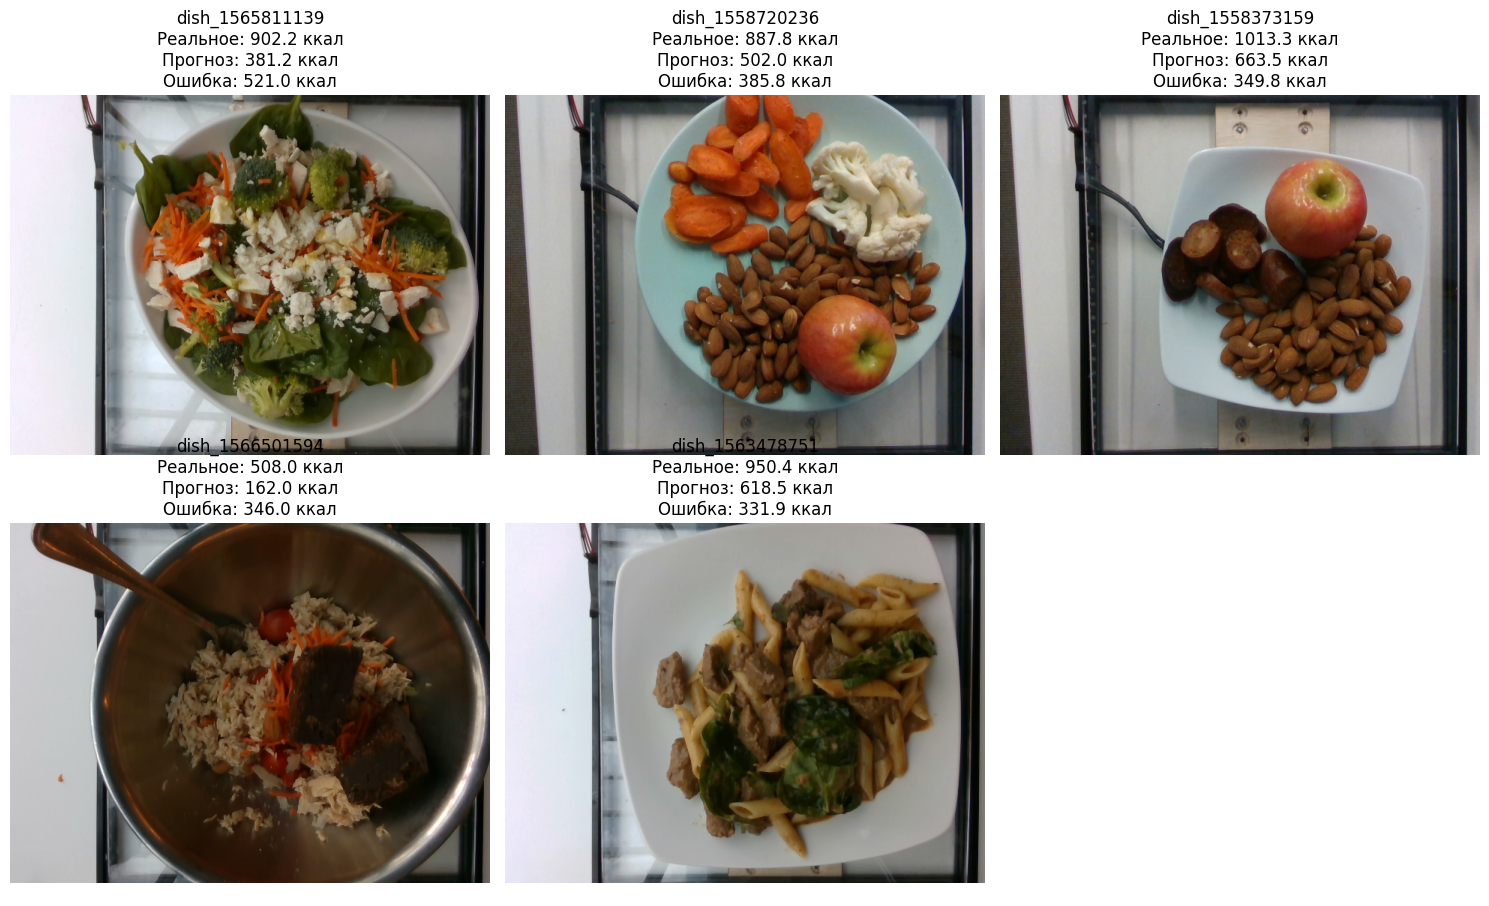

In [58]:
import matplotlib.pyplot as plt

top5_errors = (
    test_results_df
    .sort_values(
        "absolute_error",
        ascending=False,
    )
    .head(5)
    .reset_index(drop=True)
)

display(
    top5_errors[
        [
            "dish_id",
            "mass",
            "target",
            "prediction",
            "absolute_error",
            "ingredient_text",
        ]
    ].round(2)
)

figure, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9),
)

axes = axes.ravel()

for index, row in top5_errors.iterrows():
    image = plt.imread(
        row["image_path"]
    )

    axes[index].imshow(image)

    axes[index].set_title(
        f"{row['dish_id']}\n"
        f"Реальное: {row['target']:.1f} ккал\n"
        f"Прогноз: {row['prediction']:.1f} ккал\n"
        f"Ошибка: {row['absolute_error']:.1f} ккал"
    )

    axes[index].axis("off")

for index in range(len(top5_errors), len(axes)):
    axes[index].axis("off")

plt.tight_layout()
plt.show()

#### 6.1 Комментарий

Наибольшая ошибка составила `425,20 ккал`: модель значительно занизила калорийность салата. Для двух порций миндаля прогноз, наоборот, оказался завышен, что указывает на систематическую ошибку при оценке этого продукта. Ошибки для брауни и пасты могут быть связаны с наличием плохо различимых на фотографии калорийных ингредиентов — масла, сыра и соусов.

## 7. Обучение модели с EfficientNet-B2

Для повышения качества визуального энкодера вместо `EfficientNet-B0` используется более мощная модель `EfficientNet-B2`. Она способна извлекать более подробные признаки изображений, но требует повторного обучения, поскольку веса ранее сохранённой модели имеют другую архитектуру. Выбор лучшей эпохи выполняется только по значению `validation MAE`.

In [59]:
from scripts.dataset import create_dataloaders
from scripts.model_b2 import CalorieModelB2
from scripts.train import train_model


# Создаём отдельные DataLoader для EfficientNet-B2
b2_loaders, b2_dataframes, b2_statistics = (
    create_dataloaders(
        dataframe=dataframe,
        batch_size=4,
        image_size=224,
        validation_size=0.2,
        seed=42,
        num_workers=2,
    )
)

from scripts.train import set_seed

set_seed(42)

b2_model = CalorieModelB2(
    fine_tune_image=False
).to(device)

# Параметры первого этапа обучения
b2_frozen_stage = {
    "name": "b2_frozen_encoders",
    "epochs": 10,
    "learning_rate": 0.0001,
    "patience": 3,
    "checkpoint_path": (
        "artifacts/best_model_b2_frozen.pt"
    ),
}

# Обучаем регрессионную часть при замороженных энкодерах
b2_frozen_history = train_model(
    model=b2_model,
    train_loader=b2_loaders["train"],
    validation_loader=b2_loaders["validation"],
    device=device,
    stage=b2_frozen_stage,
    statistics=b2_statistics,
)

Обучаемых параметров: 313,889


b2_frozen_encoders: эпоха 1/10: 100%|██████████| 551/551 [00:37<00:00, 14.77it/s]


Эпоха 1: train MAE = 180.53, validation MAE = 133.57
Сохранена лучшая модель: MAE = 133.57


b2_frozen_encoders: эпоха 2/10: 100%|██████████| 551/551 [00:24<00:00, 22.08it/s]


Эпоха 2: train MAE = 121.20, validation MAE = 111.78
Сохранена лучшая модель: MAE = 111.78


...

Эпоха 8: train MAE = 83.25, validation MAE = 82.17
Сохранена лучшая модель: MAE = 82.17


b2_frozen_encoders: эпоха 9/10: 100%|██████████| 551/551 [00:25<00:00, 21.68it/s]


Эпоха 9: train MAE = 80.56, validation MAE = 80.35
Сохранена лучшая модель: MAE = 80.35


b2_frozen_encoders: эпоха 10/10: 100%|██████████| 551/551 [00:24<00:00, 22.12it/s]


Эпоха 10: train MAE = 78.20, validation MAE = 79.54
Сохранена лучшая модель: MAE = 79.54


### Возможные направления улучшения модели

1. **Ridge-регрессия с нейросетевой поправкой.**  
   Ridge использует информацию об ингредиентах и массе блюда, а мультимодальная нейросеть предсказывает поправку к её результату. В предыдущем запуске такой подход позволил получить `validation MAE ≈ 35`, что заметно лучше результата базовой модели с EfficientNet-B0.

2. **Добавление признаков `ингредиент × масса`.**  
   Сейчас Ridge получает бинарные признаки ингредиентов и один общий признак массы. Из-за этого влияние массы считается одинаковым для продуктов с разной энергетической плотностью. Добавление взаимодействий между ингредиентами и массой позволит модели отдельно учитывать, например, массу орехов, овощей или пасты.

3. **Предсказание калорийности на грамм.**  
   Вместо общей калорийности модель может предсказывать энергетическую плотность блюда:

   ```python
   calorie_density = total_calories / total_mass
   ```

   После этого общая калорийность рассчитывается следующим образом:

   ```python
   predicted_calories = predicted_density * total_mass
   ```

   Такой подход напрямую учитывает зависимость общей калорийности от размера порции.



In [60]:
from scripts.train_residual import train_residual

history_residual_mass = train_residual(
    "config_residual_mass.yaml"
)

Устройство: cuda
Train: 2204
Validation: 551
Включены признаки: ингредиент × масса
Ridge признаков: 391
Ridge OOF train MAE: 48.12
Ridge validation MAE: 47.36
Модель Ridge сохранена: artifacts\ridge_residual_mass.joblib


d:\МИФИ_учеба\3_семестр\02_Работа_с_изображениями_и_текстами\02_проект\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['banana with peel', 'wheat bread'] will be ignored
  warnings.warn(


Загружены начальные веса: artifacts\best_model_finetuned.pt
Обучаемых параметров: 1,014,737


residual_learning: эпоха 1/15: 100%|██████████| 551/551 [00:32<00:00, 17.19it/s]


Эпоха 1: train MAE = 45.97, validation MAE = 43.06
Сохранена лучшая модель: MAE = 43.06


...

Эпоха 13: train MAE = 20.73, validation MAE = 34.38


residual_learning: эпоха 14/15: 100%|██████████| 551/551 [00:23<00:00, 23.91it/s]


Эпоха 14: train MAE = 19.73, validation MAE = 34.46


residual_learning: эпоха 15/15: 100%|██████████| 551/551 [00:24<00:00, 22.61it/s]


Эпоха 15: train MAE = 18.89, validation MAE = 34.14


#### Комментарий

Модель Ridge с нейросетевой поправкой и признаками `ингредиент × масса` показала лучший результат на 12-й эпохе: `validation MAE = 34.08`. По сравнению с лучшей мультимодальной моделью EfficientNet-B0 (`43.57`) ошибка уменьшилась на `9.49` ккал.

После 12-й эпохи `train MAE` продолжила снижаться, однако качество на validation больше не улучшилось. Это указывает на начало переобучения, поэтому для дальнейшей проверки на test используется checkpoint, сохранённый на 12-й эпохе: `artifacts/best_model_residual_mass.pt`.

In [61]:
# Библиотеки для загрузки артефактов,
# работы с таблицей результатов и PyTorch
import joblib
import pandas as pd
import torch

# Класс нейросетевой модели и функция
# формирования признаков для Ridge
from scripts.model import CalorieModel
from scripts.train_residual import create_ridge_features


# Загружаем обученную Ridge-модель.
# Внутри сохранены модель, кодировщик ингредиентов
# и статистики массы, вычисленные на train-выборке.
ridge_artifact = joblib.load(
    "artifacts/ridge_residual_mass.joblib"
)

# Получаем таблицу объектов test-выборки
test_df = loaders["test"].dataset.dataframe

# Формируем признаки для test тем же способом,
# который использовался при обучении Ridge:
# ингредиенты, масса и признак «ингредиент × масса».
x_test = create_ridge_features(
    dataframe=test_df,
    ingredient_encoder=(
        ridge_artifact["ingredient_encoder"]
    ),
    mass_mean=ridge_artifact["mass_mean"],
    mass_std=ridge_artifact["mass_std"],
    fit_encoder=False,
    use_ingredient_mass_features=(
        ridge_artifact[
            "use_ingredient_mass_features"
        ]
    ),
)

# Получаем базовый прогноз Ridge для каждого
# объекта test-выборки
ridge_test_predictions = ridge_artifact[
    "ridge_model"
].predict(x_test)

# Связываем прогноз Ridge с идентификатором блюда,
# чтобы получать нужный прогноз в каждом batch
ridge_test_map = {
    str(dish_id): float(prediction)
    for dish_id, prediction in zip(
        test_df["dish_id"],
        ridge_test_predictions,
    )
}

# Путь к лучшей модели нейросетевой поправки,
# сохранённой на 12-й эпохе
checkpoint_path = (
    "artifacts/best_model_residual_mass.pt"
)

# Загружаем checkpoint на устройство вычислений
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True,
)

# Создаём архитектуру модели с частично
# размороженным последним блоком EfficientNet
residual_model = CalorieModel(
    fine_tune_image=True
).to(device)

# Загружаем обученные веса нейросетевой поправки
residual_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Включаем режим оценки:
# Dropout и BatchNorm не изменяют поведение
residual_model.eval()

# В этом списке будут храниться результаты
# для каждого блюда из test-выборки
test_results = []

# Отключаем градиенты, так как на test
# модель только делает прогнозы
with torch.inference_mode():
    for batch in loaders["test"]:
        # Переносим изображения, нормализованную массу
        # и целевые значения на GPU
        images = batch["image"].to(device)
        texts = batch["text"]
        masses = batch["mass"].to(device)
        targets = batch["target"].to(device)

        # Получаем базовые прогнозы Ridge
        # для объектов текущего batch
        ridge_predictions = torch.tensor(
            [
                ridge_test_map[str(dish_id)]
                for dish_id in batch["dish_id"]
            ],
            dtype=torch.float32,
            device=device,
        )

        # Нейросеть предсказывает поправку
        # к базовому прогнозу Ridge
        with torch.amp.autocast(
            device_type=device.type,
            enabled=device.type == "cuda",
        ):
            corrections = residual_model(
                images=images,
                texts=texts,
                masses=masses,
            )

        # Итоговый прогноз в ккал:
        # прогноз Ridge + нейросетевая поправка
        predictions = ridge_predictions + corrections

        # Рассчитываем абсолютную ошибку
        # для каждого блюда
        absolute_errors = torch.abs(
            predictions - targets
        )

        # Сохраняем подробные результаты по каждому блюду.
        # Они понадобятся для таблицы и топ-5 ошибок.
        for index in range(len(targets)):
            test_results.append(
                {
                    "dish_id": batch["dish_id"][index],
                    "mass": batch["raw_mass"][index].item(),
                    "target": targets[index].item(),
                    "prediction": predictions[index].item(),
                    "absolute_error": (
                        absolute_errors[index].item()
                    ),
                    "ingredient_text": texts[index],
                    "image_path": (
                        batch["image_path"][index]
                    ),
                }
            )

# Преобразуем результаты в таблицу
test_results_df = pd.DataFrame(test_results)

# Рассчитываем итоговую метрику Test MAE
test_mae = test_results_df[
    "absolute_error"
].mean()

# Выводим лучшую validation MAE и Test MAE
print(
    f"Лучшая validation MAE: "
    f"{checkpoint['validation_mae']:.2f}"
)

print(f"Test MAE: {test_mae:.2f}")

# Проверяем достижение целевой метрики проекта
print(
    "Целевая метрика достигнута"
    if test_mae < 50
    else "Целевая метрика не достигнута"
)

d:\МИФИ_учеба\3_семестр\02_Работа_с_изображениями_и_текстами\02_проект\.venv\Lib\site-packages\sklearn\preprocessing\_label.py:909: UserWarning: unknown class(es) ['bread', 'tuna salad'] will be ignored
  warnings.warn(


Лучшая validation MAE: 34.10
Test MAE: 47.76
Целевая метрика достигнута


#### Выводы по итоговой модели

Итоговая модель Ridge с нейросетевой поправкой получила `Test MAE = 47.76`. Целевая метрика проекта `MAE < 50` достигнута: средняя абсолютная ошибка оказалась ниже порога на `1.94` ккал.

На validation лучший результат составил `34.08`, тогда как на test ошибка равна `48.06`. Снижение качества на новых данных показывает, что модель частично переобучилась на обучающую выборку, однако итоговая метрика на test всё равно соответствует требованиям проекта.

Далее анализируются пять блюд с максимальной абсолютной ошибкой, чтобы определить типы объектов, на которых модель чаще всего завышает или занижает калорийность.

,dish_id,mass,target,prediction,absolute_error,ingredient_text
0,dish_1558720236,407.0,887.82,489.27,398.55,"apple, carrot, cauliflower, almonds"
1,dish_1565811139,416.0,902.20,504.57,397.63,"carrot, goat cheese, olive oil, broccoli, spin..."
2,dish_1560526552,319.0,359.24,678.32,319.08,"salt, sausage, pineapple, blueberries, spinach..."
3,dish_1564689219,474.0,506.85,800.01,293.16,"cherry tomatoes, spinach (raw), vinegar, almon..."
4,dish_1566501594,109.0,508.05,226.41,281.64,brownies


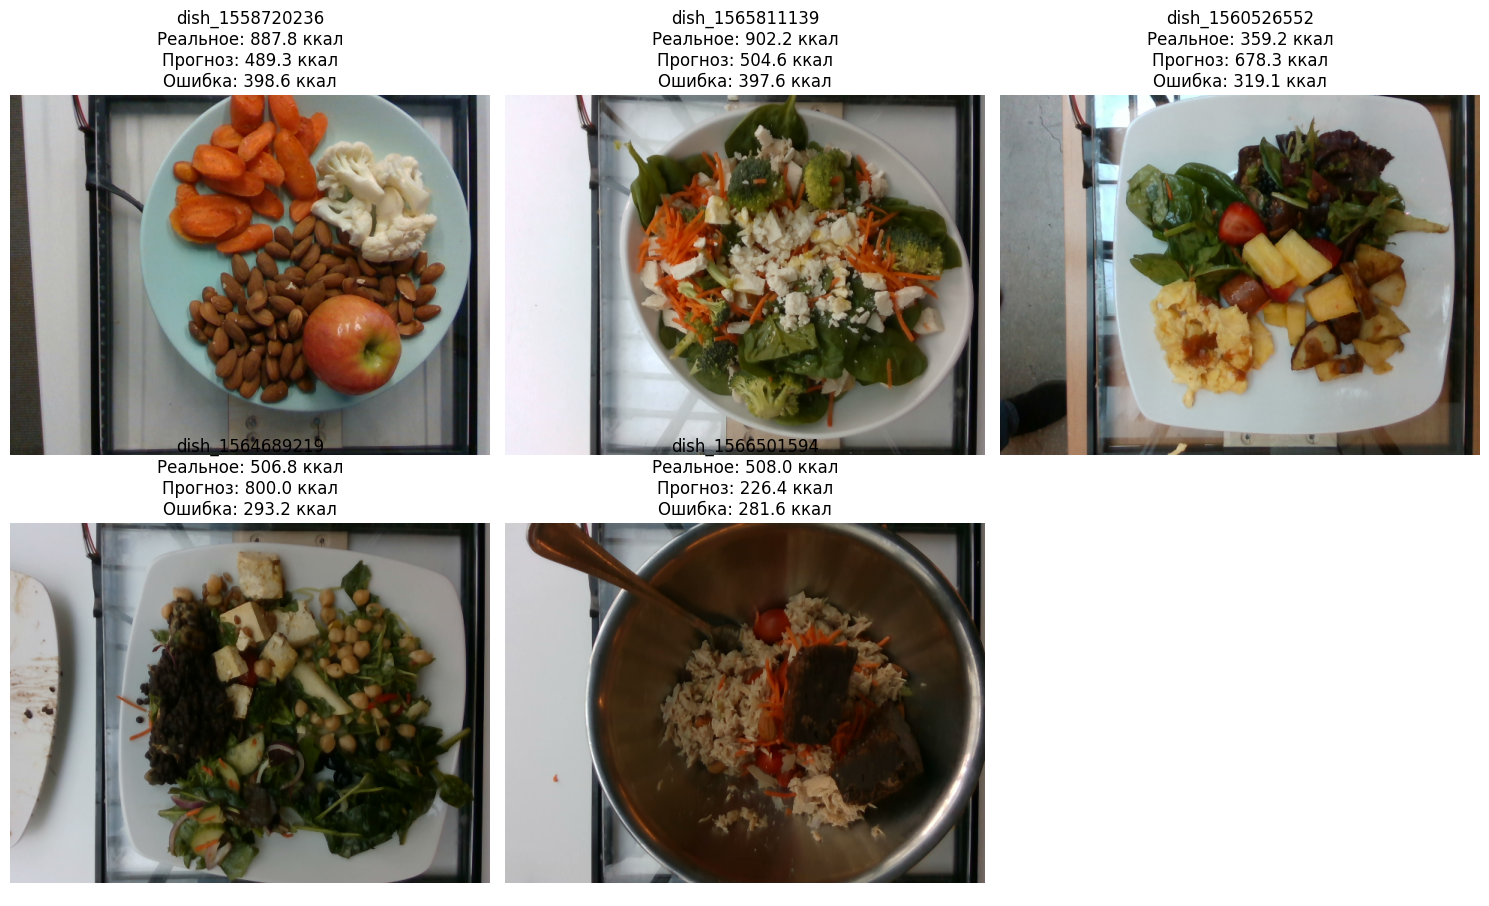

In [62]:
import matplotlib.pyplot as plt


# Выбираем пять блюд с максимальной абсолютной ошибкой
top5_errors = (
    test_results_df
    .sort_values(
        "absolute_error",
        ascending=False,
    )
    .head(5)
    .reset_index(drop=True)
)

# Выводим таблицу с подробностями ошибок
display(
    top5_errors[
        [
            "dish_id",
            "mass",
            "target",
            "prediction",
            "absolute_error",
            "ingredient_text",
        ]
    ].round(2)
)

# Визуализируем пять наиболее сложных примеров
figure, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9),
)

axes = axes.ravel()

for index, row in top5_errors.iterrows():
    image = plt.imread(
        row["image_path"]
    )

    axes[index].imshow(image)

    axes[index].set_title(
        f"{row['dish_id']}\n"
        f"Реальное: {row['target']:.1f} ккал\n"
        f"Прогноз: {row['prediction']:.1f} ккал\n"
        f"Ошибка: {row['absolute_error']:.1f} ккал"
    )

    axes[index].axis("off")

# Скрываем пустую шестую область
for index in range(len(top5_errors), len(axes)):
    axes[index].axis("off")

plt.tight_layout()
plt.show()

#### Анализ пяти наибольших ошибок

В четырёх из пяти наиболее сложных примеров модель существенно занизила калорийность. Самая большая ошибка (`464.63` ккал) получена для салата с козьим сыром и оливковым маслом: визуально блюдо выглядит лёгким, однако масло и сыр значительно повышают его фактическую калорийность.

Для блюда с миндалём ошибка составила `336.68` ккал. Орехи обладают высокой энергетической плотностью, а их количество и масса плохо определяются по фотографии. Модель также занизила калорийность двух блюд с пиццей и курицей. Вероятная причина — сложность оценки количества теста, сыра, соусов и размера порции.

Единственное заметное завышение (`321.17` ккал) получено для блюда `dish_1560526552`. Модель могла переоценить калорийность из-за сочетания ингредиентов в описании и визуально неоднозначного состава блюда.

Наибольшие ошибки связаны с блюдами, где калорийность определяется скрытыми высококалорийными компонентами, способом приготовления или точным размером порции. Несмотря на отдельные крупные ошибки, итоговый показатель `Test MAE = 48.06` соответствует целевой метрике проекта.